# Run Model Tests

Use this notebook to run the current MILP models on selected scenario data and save the results to Excel. Edit only the parameter cell below for normal use, then run the remaining cells in order.

In [1]:
# ===== Parameters you usually edit =====

# Choose which current model to run: "single", "multi", or "both".
MODEL = "both"

# Choose the data to test.
# Use None to use the default checked-in folder for the selected MODEL.
# Or provide one or more folders/files to use the same input for each selected model, for example:
# SCENARIO_INPUTS = ["synthetic_data_generator/multicommodity_scenarios/F4_operational_conflict_M"]
# SCENARIO_INPUTS = ["synthetic_data_generator/multicommodity_scenarios/F1_system_scale_L/seed_001/F1_system_scale_L_seed_001.json"]
# For MODEL = "both", you may also provide separate inputs:
# SCENARIO_INPUTS = {
#     "single": ["synthetic_data_generator/singlecommodity_scenarios"],
#     "multi": ["synthetic_data_generator/multicommodity_scenarios"],
# }
SCENARIO_INPUTS = None

# Use None to run every scenario found, or an integer for a quick smoke test.
MAX_SCENARIOS = None

# Per-scenario Gurobi time limit in seconds. Use None for no explicit limit.
TIME_LIMIT_SECONDS = 600

# Number of scenario solves to run at the same time.
# Start with 2, then increase only if the machine and Gurobi license handle it well.
WORKERS = 10

# Optional Gurobi Threads value per scenario solve.
# Recommended: 1 when WORKERS > 1, or None when running one scenario at a time.
THREADS_PER_SOLVE = 1

# False = penalised overflow variant; True = strict no-overflow variant.
STRICT_CAPACITY = False

# Output file names. Use None to use default names for the selected MODEL.
# For MODEL = "both", default output creates one Excel file per model.
# You can also provide a dictionary with separate names for "single" and "multi".
EXCEL_PATH = None

# Optional CSV output. Leave as None if you only want Excel.
CSV_PATH = None

# Save detailed per-scenario solution JSON files for later plotting/review.
SAVE_PAYLOADS = True

# Save PNG plots from the solution payloads.
# If this is True, payloads are saved even when SAVE_PAYLOADS is False.
MAKE_PLOTS = True

# Use None for default output folders, or set a folder path.
# For MODEL = "both", a custom folder is split into single/ and multi/ subfolders.
PAYLOAD_DIR = None
PLOT_DIR = None

# Show a few generated PNG plots inside the notebook after saving them.
PREVIEW_PLOTS = True
MAX_PLOT_PREVIEWS = 6

## Setup

In [2]:
import os
import sys
from pathlib import Path

# Find the repository root from the notebook location/current working directory.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = next((path for path in candidates if (path / "scenario_runner.py").exists()), cwd)
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scenario_runner import print_results, run_scenarios, scenario_paths, write_csv, write_xlsx
from solution_payloads import plot_payload_results
from monolithic_milp import build_model as build_single_model, load_scenario as load_single_scenario
from multicommodity_milp import build_model as build_multi_model, load_scenario as load_multi_scenario

DEFAULTS = {
    "single": {
        "model_label": "single_commodity",
        "scenario_dir": "synthetic_data_generator/singlecommodity_scenarios",
        "excel_path": "results/singlecommodity_results.xlsx",
        "payload_dir": "results/payloads/single_commodity",
        "plot_dir": "results/plots/single_commodity",
        "load_scenario": load_single_scenario,
        "build_model": build_single_model,
    },
    "multi": {
        "model_label": "multi_commodity",
        "scenario_dir": "synthetic_data_generator/multicommodity_scenarios",
        "excel_path": "results/multicommodity_results.xlsx",
        "payload_dir": "results/payloads/multi_commodity",
        "plot_dir": "results/plots/multi_commodity",
        "load_scenario": load_multi_scenario,
        "build_model": build_multi_model,
    },
}

model_key = MODEL.strip().lower()
if model_key == "both":
    selected_model_keys = ["single", "multi"]
elif model_key in DEFAULTS:
    selected_model_keys = [model_key]
else:
    raise ValueError('MODEL must be "single", "multi", or "both"')

def inputs_for_model(value, key, default_dir):
    if value is None:
        return [default_dir]
    if isinstance(value, dict):
        selected = value.get(key)
        if selected is None:
            return [default_dir]
        return selected if isinstance(selected, (list, tuple)) else [selected]
    return value if isinstance(value, (list, tuple)) else [value]

def output_for_model(value, key, default_path):
    if value is None:
        return default_path
    if isinstance(value, dict):
        return value.get(key, default_path)
    if model_key == "both" and value:
        stem, ext = os.path.splitext(value)
        return f"{stem}_{key}{ext or '.xlsx'}"
    return value

def output_dir_for_model(value, key, default_dir):
    if value is None:
        return default_dir
    if isinstance(value, dict):
        return value.get(key, default_dir)
    if model_key == "both":
        return os.path.join(value, key)
    return value

model_runs = []
for key in selected_model_keys:
    config = dict(DEFAULTS[key])
    config["key"] = key
    config["inputs"] = inputs_for_model(SCENARIO_INPUTS, key, config["scenario_dir"])
    config["excel_output"] = output_for_model(EXCEL_PATH, key, config["excel_path"])
    config["csv_output"] = output_for_model(CSV_PATH, key, None) if CSV_PATH else None
    config["payload_output"] = output_dir_for_model(PAYLOAD_DIR, key, config["payload_dir"]) if (SAVE_PAYLOADS or MAKE_PLOTS) else None
    config["plot_output"] = output_dir_for_model(PLOT_DIR, key, config["plot_dir"]) if MAKE_PLOTS else None
    model_runs.append(config)

print(f"Project root: {PROJECT_ROOT}")
print(f"Model selection: {MODEL}")
for config in model_runs:
    print(f"- {config['model_label']}")
    print(f"  Scenario input(s): {config['inputs']}")
    print(f"  Excel output: {config['excel_output']}")
    print(f"  CSV output: {config['csv_output'] or '-'}")
    print(f"  Payload output: {config['payload_output'] or '-'}")
    print(f"  Plot output: {config['plot_output'] or '-'}")
print(f"Time limit: {TIME_LIMIT_SECONDS if TIME_LIMIT_SECONDS is not None else 'none'} seconds")
print(f"Workers: {WORKERS}")
print(f"Threads per solve: {THREADS_PER_SOLVE if THREADS_PER_SOLVE is not None else '-'}")
print(f"Strict capacity: {STRICT_CAPACITY}")

Project root: C:\Ponpot_Work_Space\math4003-port-yard-optimisation
Model selection: both
- single_commodity
  Scenario input(s): ['synthetic_data_generator/singlecommodity_scenarios']
  Excel output: results/singlecommodity_results.xlsx
  CSV output: -
  Payload output: results/payloads/single_commodity
  Plot output: results/plots/single_commodity
- multi_commodity
  Scenario input(s): ['synthetic_data_generator/multicommodity_scenarios']
  Excel output: results/multicommodity_results.xlsx
  CSV output: -
  Payload output: results/payloads/multi_commodity
  Plot output: results/plots/multi_commodity
Time limit: 600 seconds
Workers: 10
Threads per solve: 1
Strict capacity: False


## Select Scenarios

In [3]:
for config in model_runs:
    paths = scenario_paths(config["inputs"])
    if MAX_SCENARIOS is not None:
        paths = paths[:MAX_SCENARIOS]

    if not paths:
        raise FileNotFoundError(f"No scenario JSON files found in: {config['inputs']}")

    config["paths"] = paths
    print(f"{config['model_label']}: selected {len(paths)} scenario(s).")
    for path in paths[:10]:
        print("-", path)
    if len(paths) > 10:
        print(f"... plus {len(paths) - 10} more")
    print()

single_commodity: selected 120 scenario(s).
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_001\F1_system_scale_H_seed_001.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_002\F1_system_scale_H_seed_002.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_003\F1_system_scale_H_seed_003.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_004\F1_system_scale_H_seed_004.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_005\F1_system_scale_H_seed_005.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_006\F1_system_scale_H_seed_006.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_007\F1_system_scale_H_seed_007.json
- synthetic_data_generator\singlecommodity_scenarios\F1_system_scale_H\seed_008\F1_system_scale_H_seed_008.json
- synthetic_data_generator\singlecommodity_scenarios\F1_syst

## Run Optimisation

In [4]:
results_by_model = {}
results = []

for config in model_runs:
    print(f"=== {config['model_label']} ===")
    model_results = run_scenarios(
        paths=config["paths"],
        model_label=config["model_label"],
        load_scenario=config["load_scenario"],
        build_model=config["build_model"],
        strict_capacity=STRICT_CAPACITY,
        time_limit_seconds=TIME_LIMIT_SECONDS,
        threads_per_solve=THREADS_PER_SOLVE,
        payload_dir=config["payload_output"],
        workers=WORKERS,
        show_progress=True,
    )
    results_by_model[config["key"]] = model_results
    results.extend(model_results)
    print()
    print_results(model_results)
    print()

=== single_commodity ===
Running 120 scenario(s) with 10 worker process(es).
[1/120] F1_system_scale_H_seed_010: OPTIMAL
[2/120] F1_system_scale_L_seed_001: OPTIMAL
[3/120] F1_system_scale_L_seed_002: OPTIMAL
[4/120] F1_system_scale_H_seed_003: OPTIMAL
[5/120] F1_system_scale_L_seed_004: OPTIMAL
[6/120] F1_system_scale_L_seed_005: OPTIMAL
[7/120] F1_system_scale_L_seed_003: OPTIMAL
[8/120] F1_system_scale_L_seed_007: OPTIMAL
[9/120] F1_system_scale_L_seed_006: OPTIMAL
[10/120] F1_system_scale_H_seed_004: OPTIMAL
[11/120] F1_system_scale_L_seed_009: OPTIMAL
[12/120] F1_system_scale_H_seed_001: OPTIMAL
[13/120] F1_system_scale_L_seed_010: OPTIMAL
[14/120] F1_system_scale_H_seed_002: OPTIMAL
[15/120] F1_system_scale_H_seed_009: OPTIMAL
[16/120] F1_system_scale_H_seed_005: OPTIMAL
[17/120] F1_system_scale_M_seed_005: OPTIMAL
[18/120] F1_system_scale_M_seed_003: OPTIMAL
[19/120] F1_system_scale_M_seed_004: OPTIMAL
[20/120] F1_system_scale_M_seed_006: OPTIMAL
[21/120] F1_system_scale_M_seed_

## Review Results

In [5]:
try:
    import pandas as pd

    results_table = pd.DataFrame(results)
    display(results_table)
except ImportError:
    print_results(results)
    results_table = results

,model,scenario,family,seed,status,objective,runtime_seconds,mip_gap,best_bound,solution_count,num_vars,num_binary_vars,num_constraints,strict_capacity,time_limit_seconds,threads_per_solve,scenario_path,payload_path,plot_path,error
0,single_commodity,F1_system_scale_H_seed_001,F1_system_scale_H,001,OPTIMAL,2.904669e+07,14.401,0.000000e+00,2.904669e+07,7,21918,4908,32320,False,600,1,synthetic_data_generator\singlecommodity_scena...,results/payloads/single_commodity\F1_system_sc...,None,None
1,single_commodity,F1_system_scale_H_seed_002,F1_system_scale_H,002,OPTIMAL,2.687243e+07,15.609,0.000000e+00,2.687243e+07,8,21975,4965,32320,False,600,1,synthetic_data_generator\singlecommodity_scena...,results/payloads/single_commodity\F1_system_sc...,None,None
2,single_commodity,F1_system_scale_H_seed_003,F1_system_scale_H,003,OPTIMAL,3.038005e+07,7.913,9.479906e-05,3.038293e+07,5,21735,4725,32320,False,600,1,synthetic_data_generator\singlecommodity_scena...,results/payloads/single_commodity\F1_system_sc...,None,None
3,single_commodity,F1_system_scale_H_seed_004,F1_system_scale_H,004,OPTIMAL,3.000221e+07,12.943,9.599293e-05,3.000509e+07,9,22068,5058,32320,False,600,1,synthetic_data_generator\singlecommodity_scena...,results/payloads/single_commodity\F1_system_sc...,None,None
4,single_commodity,F1_system_scale_H_seed_005,F1_system_scale_H,005,OPTIMAL,3.235879e+07,15.747,1.151245e-16,3.235879e+07,10,21813,4803,32320,False,600,1,synthetic_data_generator\singlecommodity_scena...,results/payloads/single_commodity\F1_system_sc...,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,multi_commodity,F4_operational_conflict_M_seed_006,F4_operational_conflict_M,006,OPTIMAL,1.769255e+07,58.995,0.000000e+00,1.769255e+07,6,28620,2970,26790,False,600,1,synthetic_data_generator\multicommodity_scenar...,results/payloads/multi_commodity\F4_operationa...,None,None
236,multi_commodity,F4_operational_conflict_M_seed_007,F4_operational_conflict_M,007,INF_OR_UNBD,NaN,17.624,NaN,NaN,0,28539,2889,26790,False,600,1,synthetic_data_generator\multicommodity_scenar...,NaN,None,None
237,multi_commodity,F4_operational_conflict_M_seed_008,F4_operational_conflict_M,008,OPTIMAL,1.842503e+07,40.692,7.567347e-05,1.842642e+07,8,28611,2961,26790,False,600,1,synthetic_data_generator\multicommodity_scenar...,results/payloads/multi_commodity\F4_operationa...,None,None
238,multi_commodity,F4_operational_conflict_M_seed_009,F4_operational_conflict_M,009,OPTIMAL,1.817879e+07,25.191,6.601099e-05,1.817999e+07,3,28635,2985,26790,False,600,1,synthetic_data_generator\multicommodity_scenar...,results/payloads/multi_commodity\F4_operationa...,None,None


## Save Outputs

In [6]:
for config in model_runs:
    model_results = results_by_model.get(config["key"], [])
    if config["plot_output"]:
        plot_paths = plot_payload_results(model_results, config["plot_output"])
        print(f"Saved {len(plot_paths)} {config['model_label']} PNG plot(s) to {config['plot_output']}")

    if config["payload_output"]:
        payload_count = sum(1 for result in model_results if result.get("payload_path"))
        print(f"Saved {payload_count} {config['model_label']} payload(s) to {config['payload_output']}")

    if config["excel_output"]:
        write_xlsx(model_results, config["excel_output"])
        print(f"Saved {config['model_label']} Excel results to {config['excel_output']}")

    if config["csv_output"]:
        write_csv(model_results, config["csv_output"])
        print(f"Saved {config['model_label']} CSV results to {config['csv_output']}")

Saved 118 single_commodity PNG plot(s) to results/plots/single_commodity
Saved 118 single_commodity payload(s) to results/payloads/single_commodity
Saved single_commodity Excel results to results/singlecommodity_results.xlsx
Saved 118 multi_commodity PNG plot(s) to results/plots/multi_commodity
Saved 118 multi_commodity payload(s) to results/payloads/multi_commodity
Saved multi_commodity Excel results to results/multicommodity_results.xlsx


## Preview Plots

Showing 6 of 236 generated PNG plot(s).

**results/plots/single_commodity\F1_system_scale_H_seed_001.png**

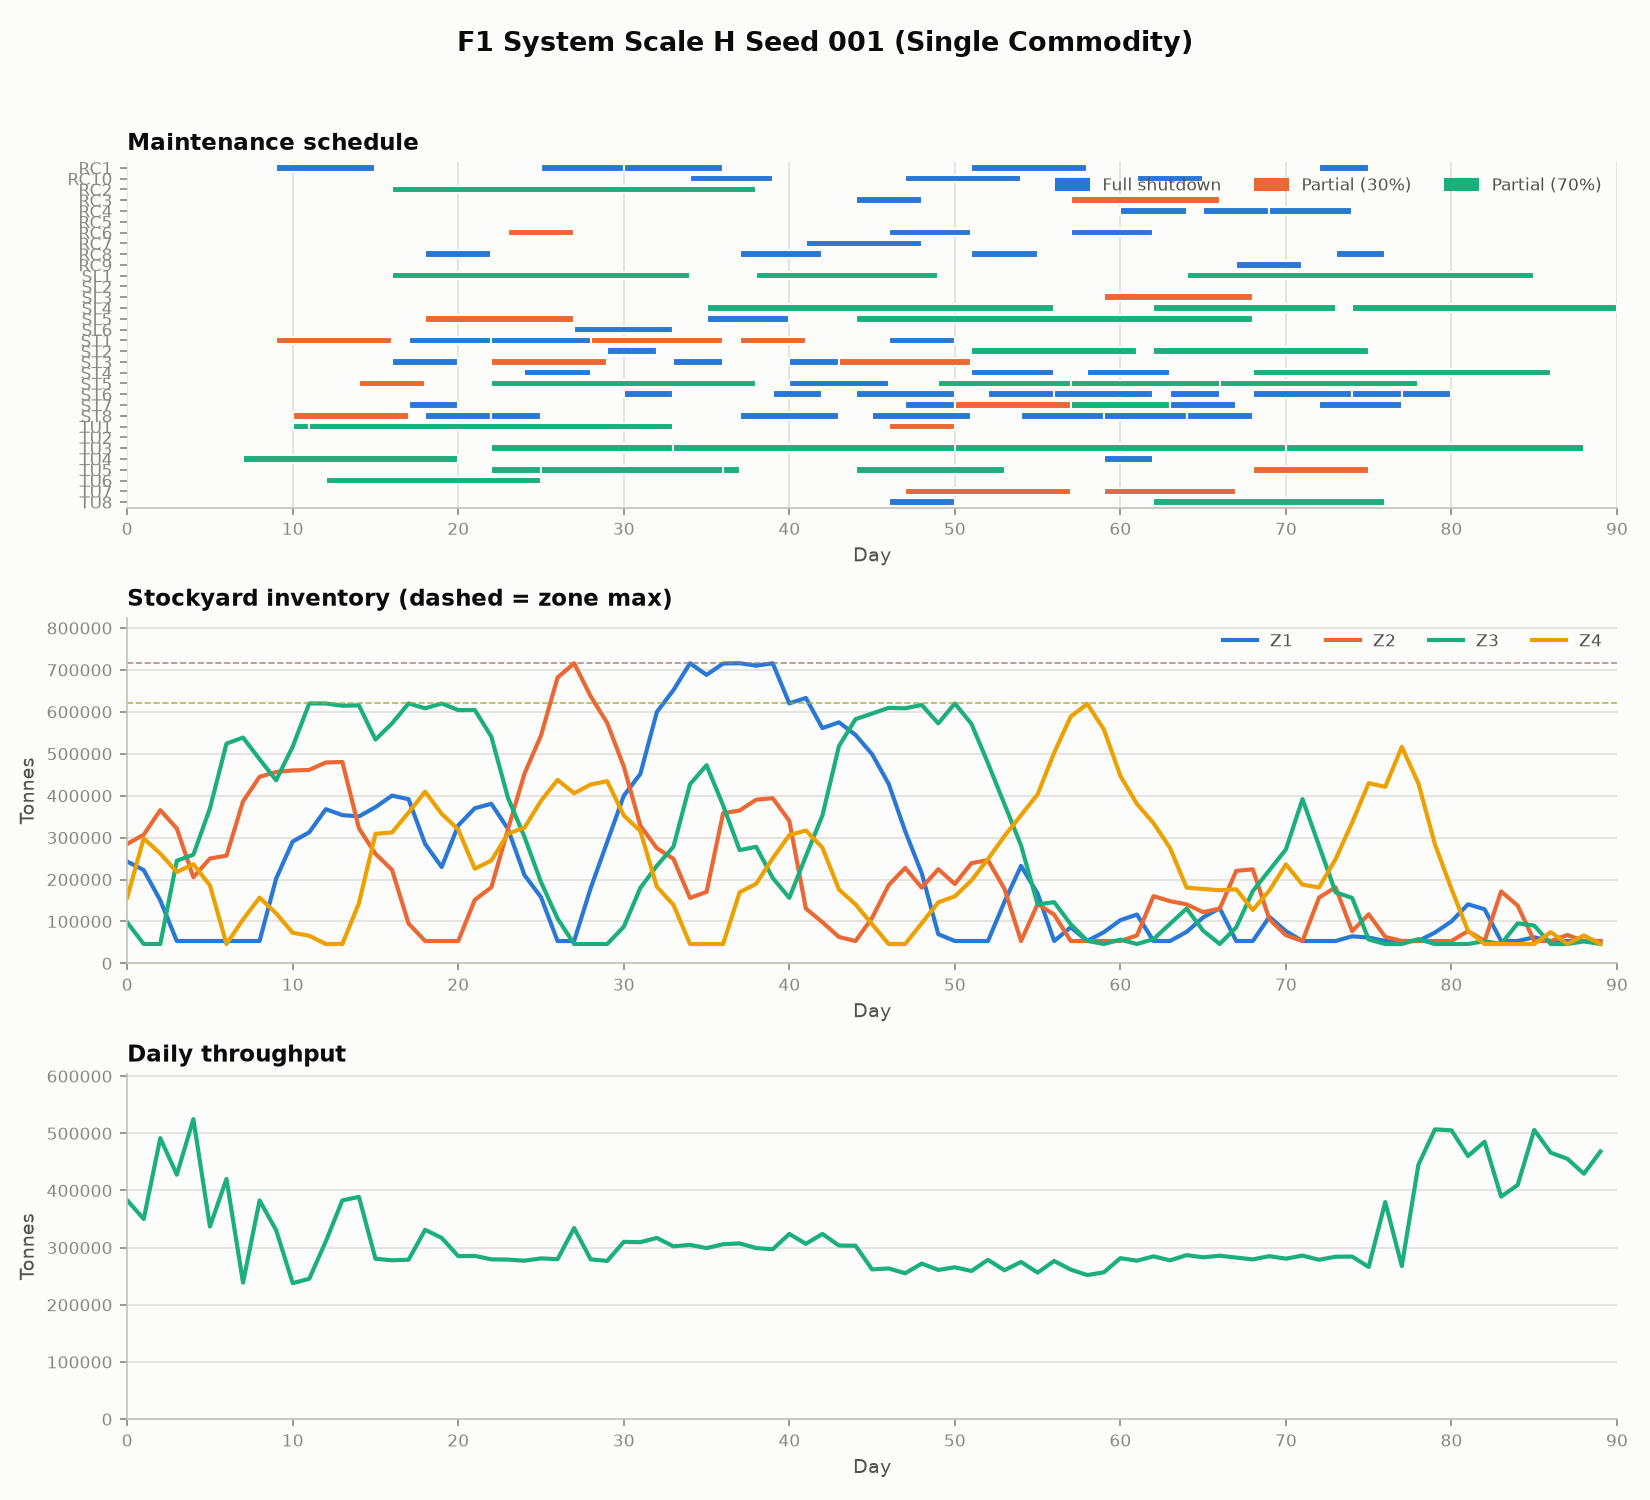

**results/plots/single_commodity\F1_system_scale_H_seed_002.png**

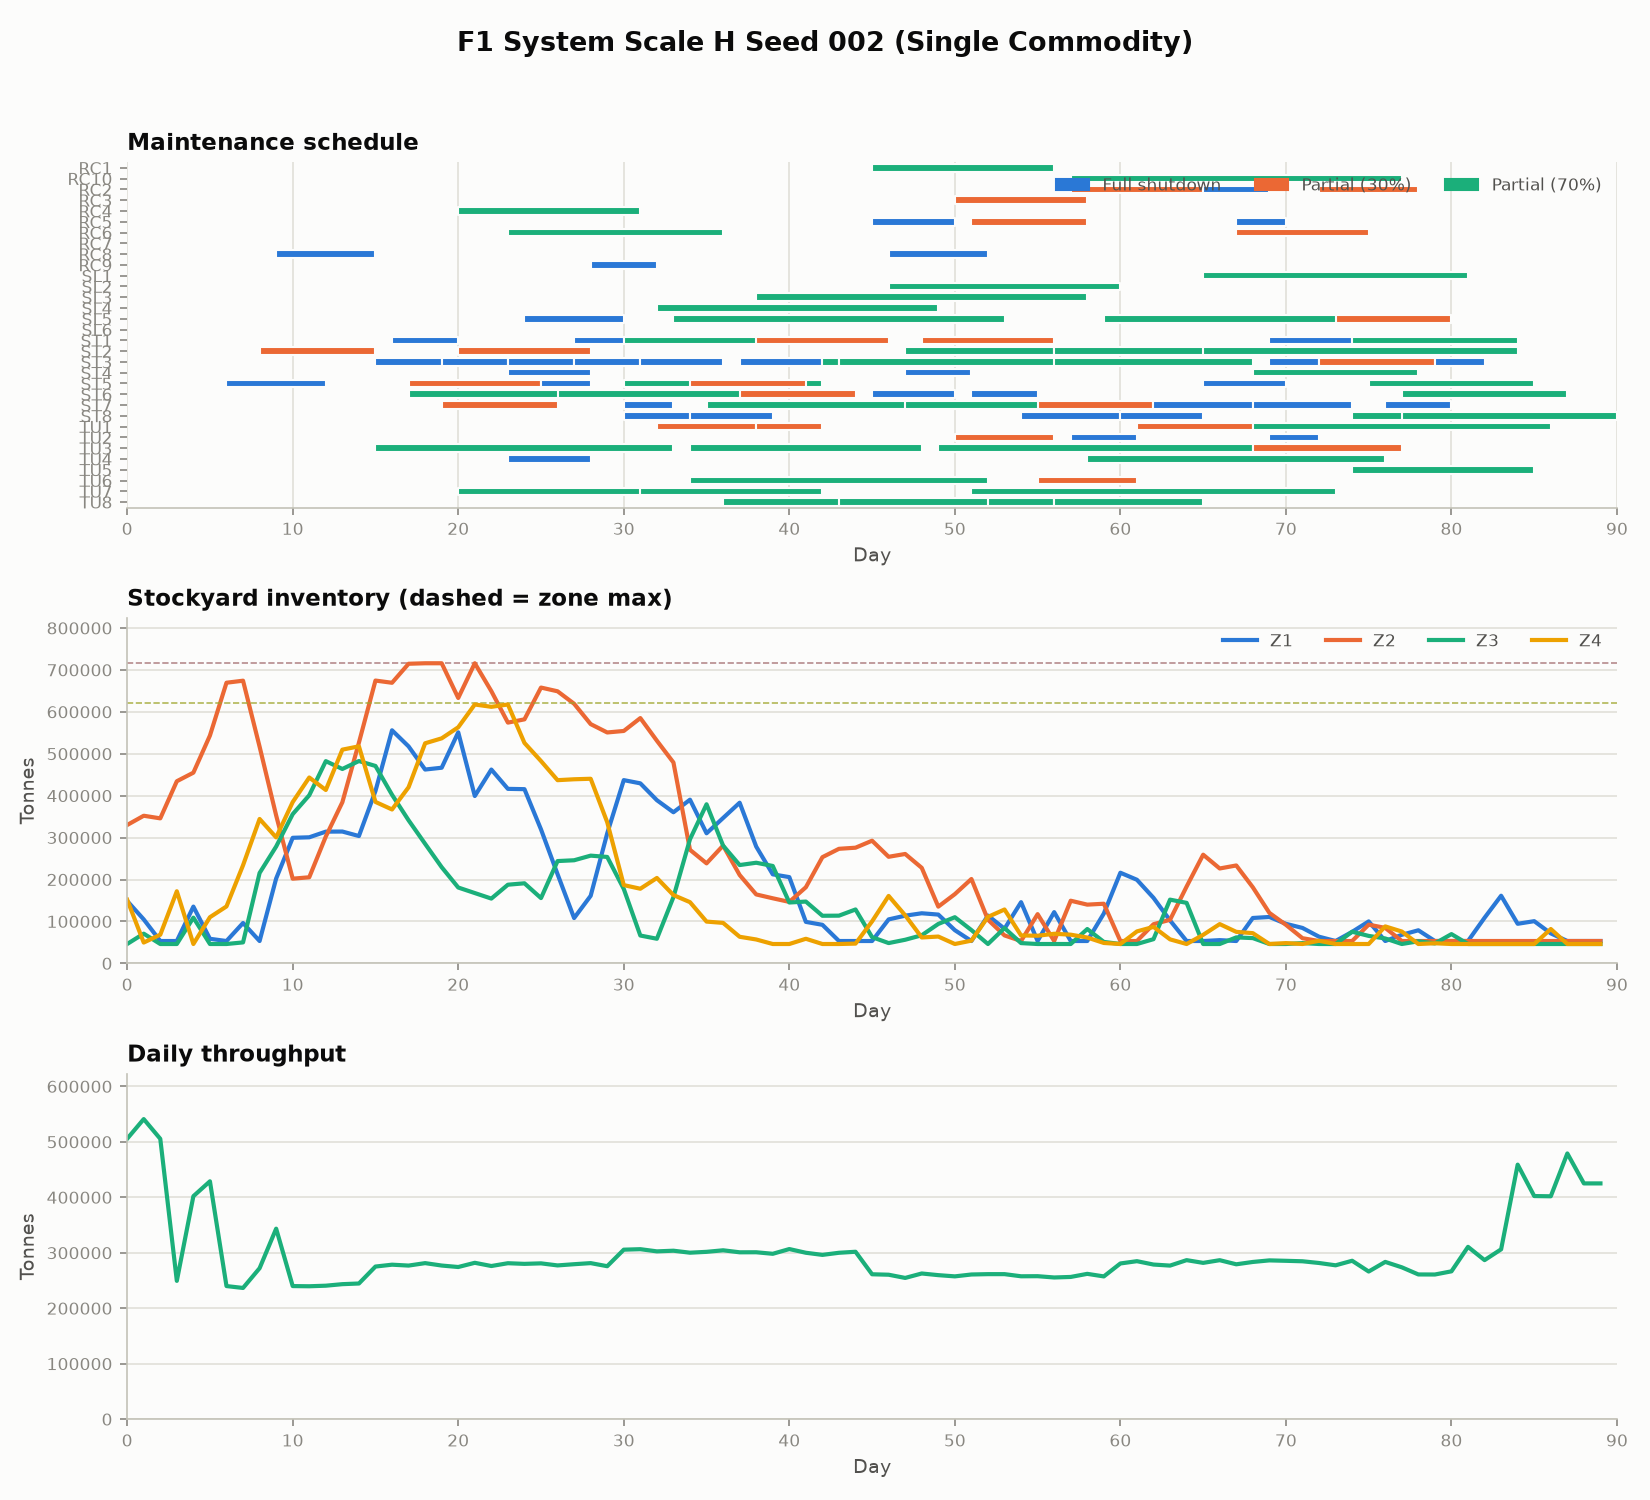

**results/plots/single_commodity\F1_system_scale_H_seed_003.png**

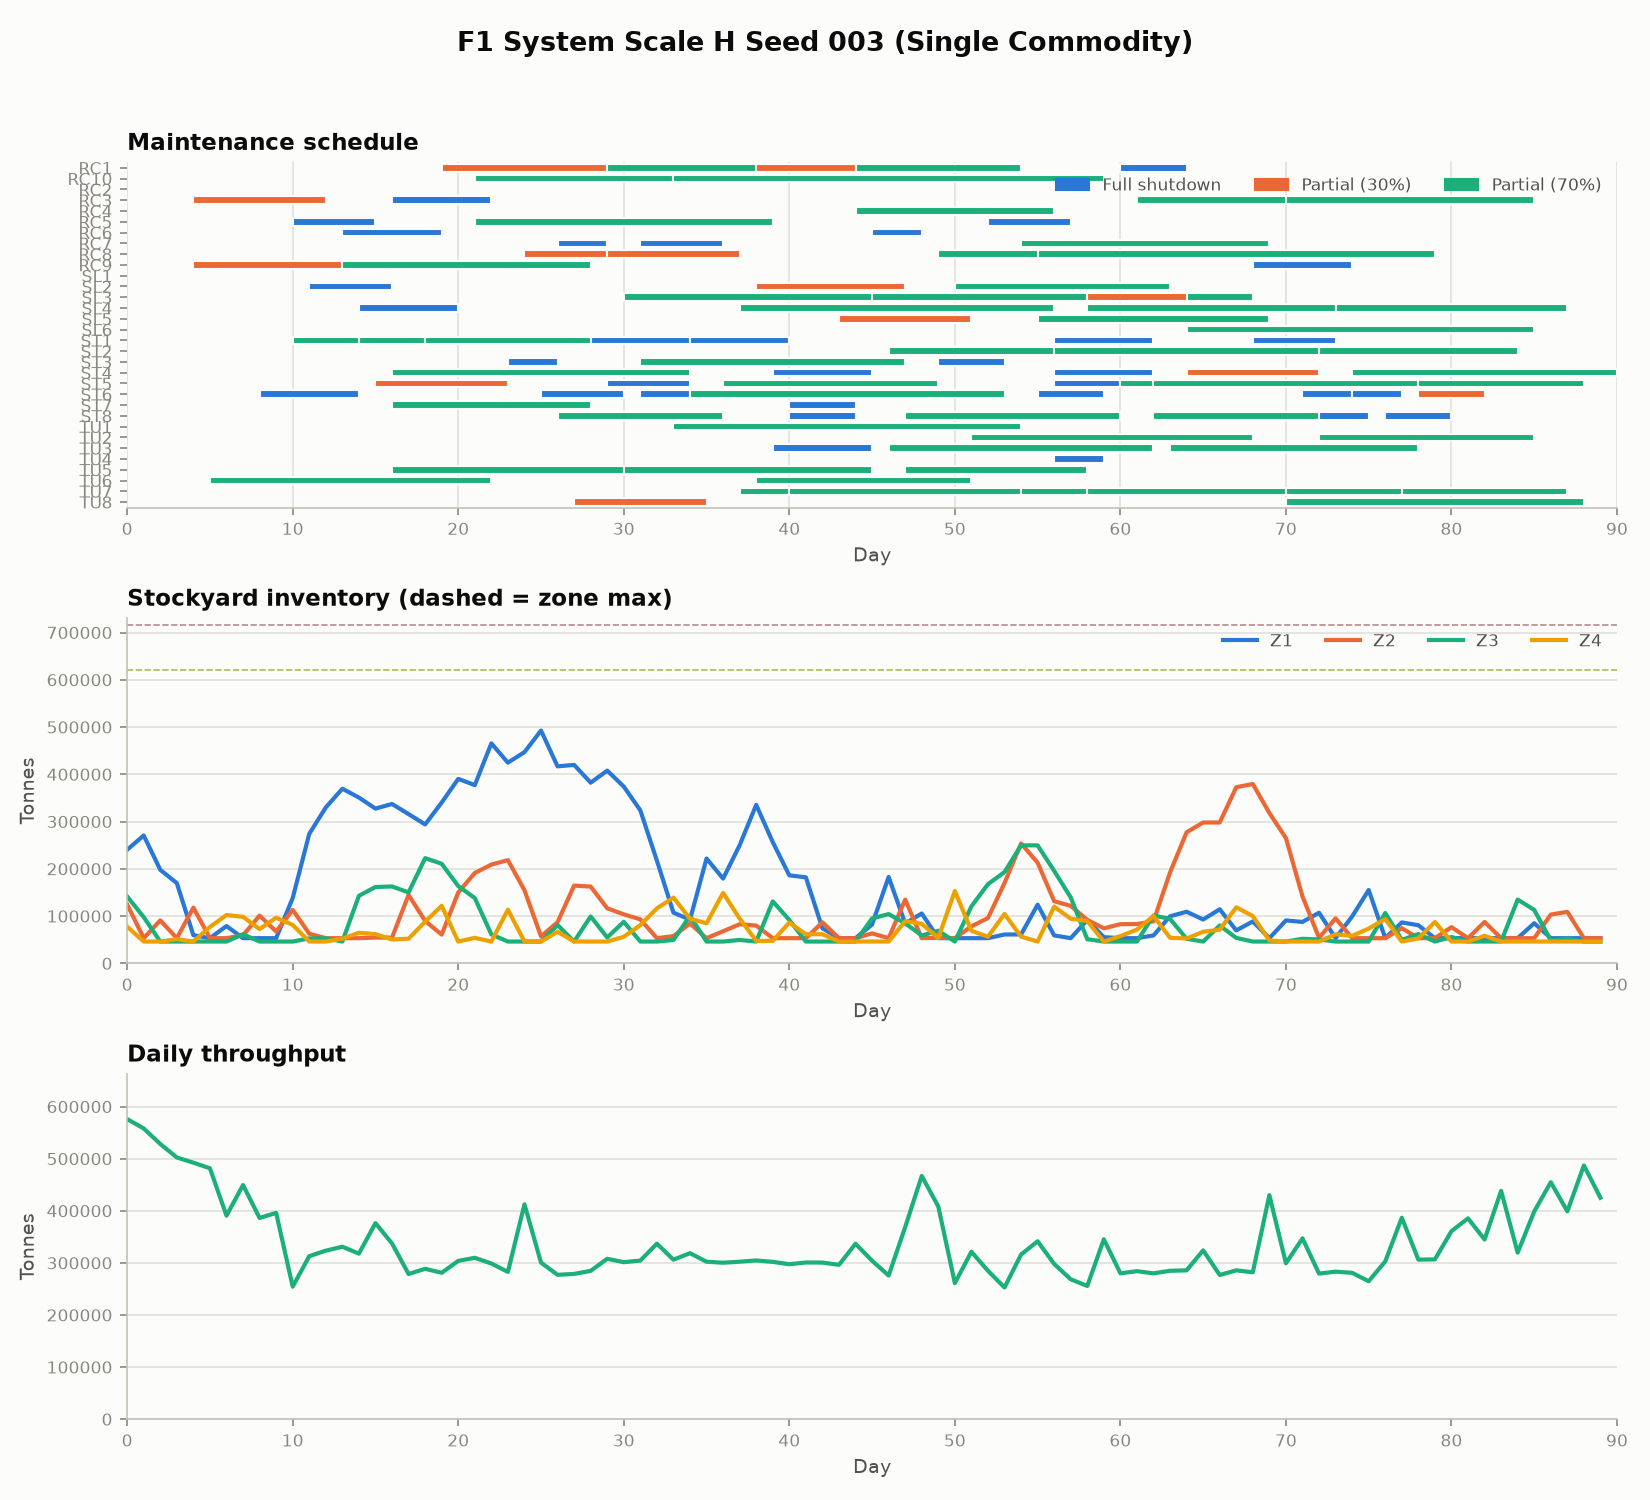

**results/plots/single_commodity\F1_system_scale_H_seed_004.png**

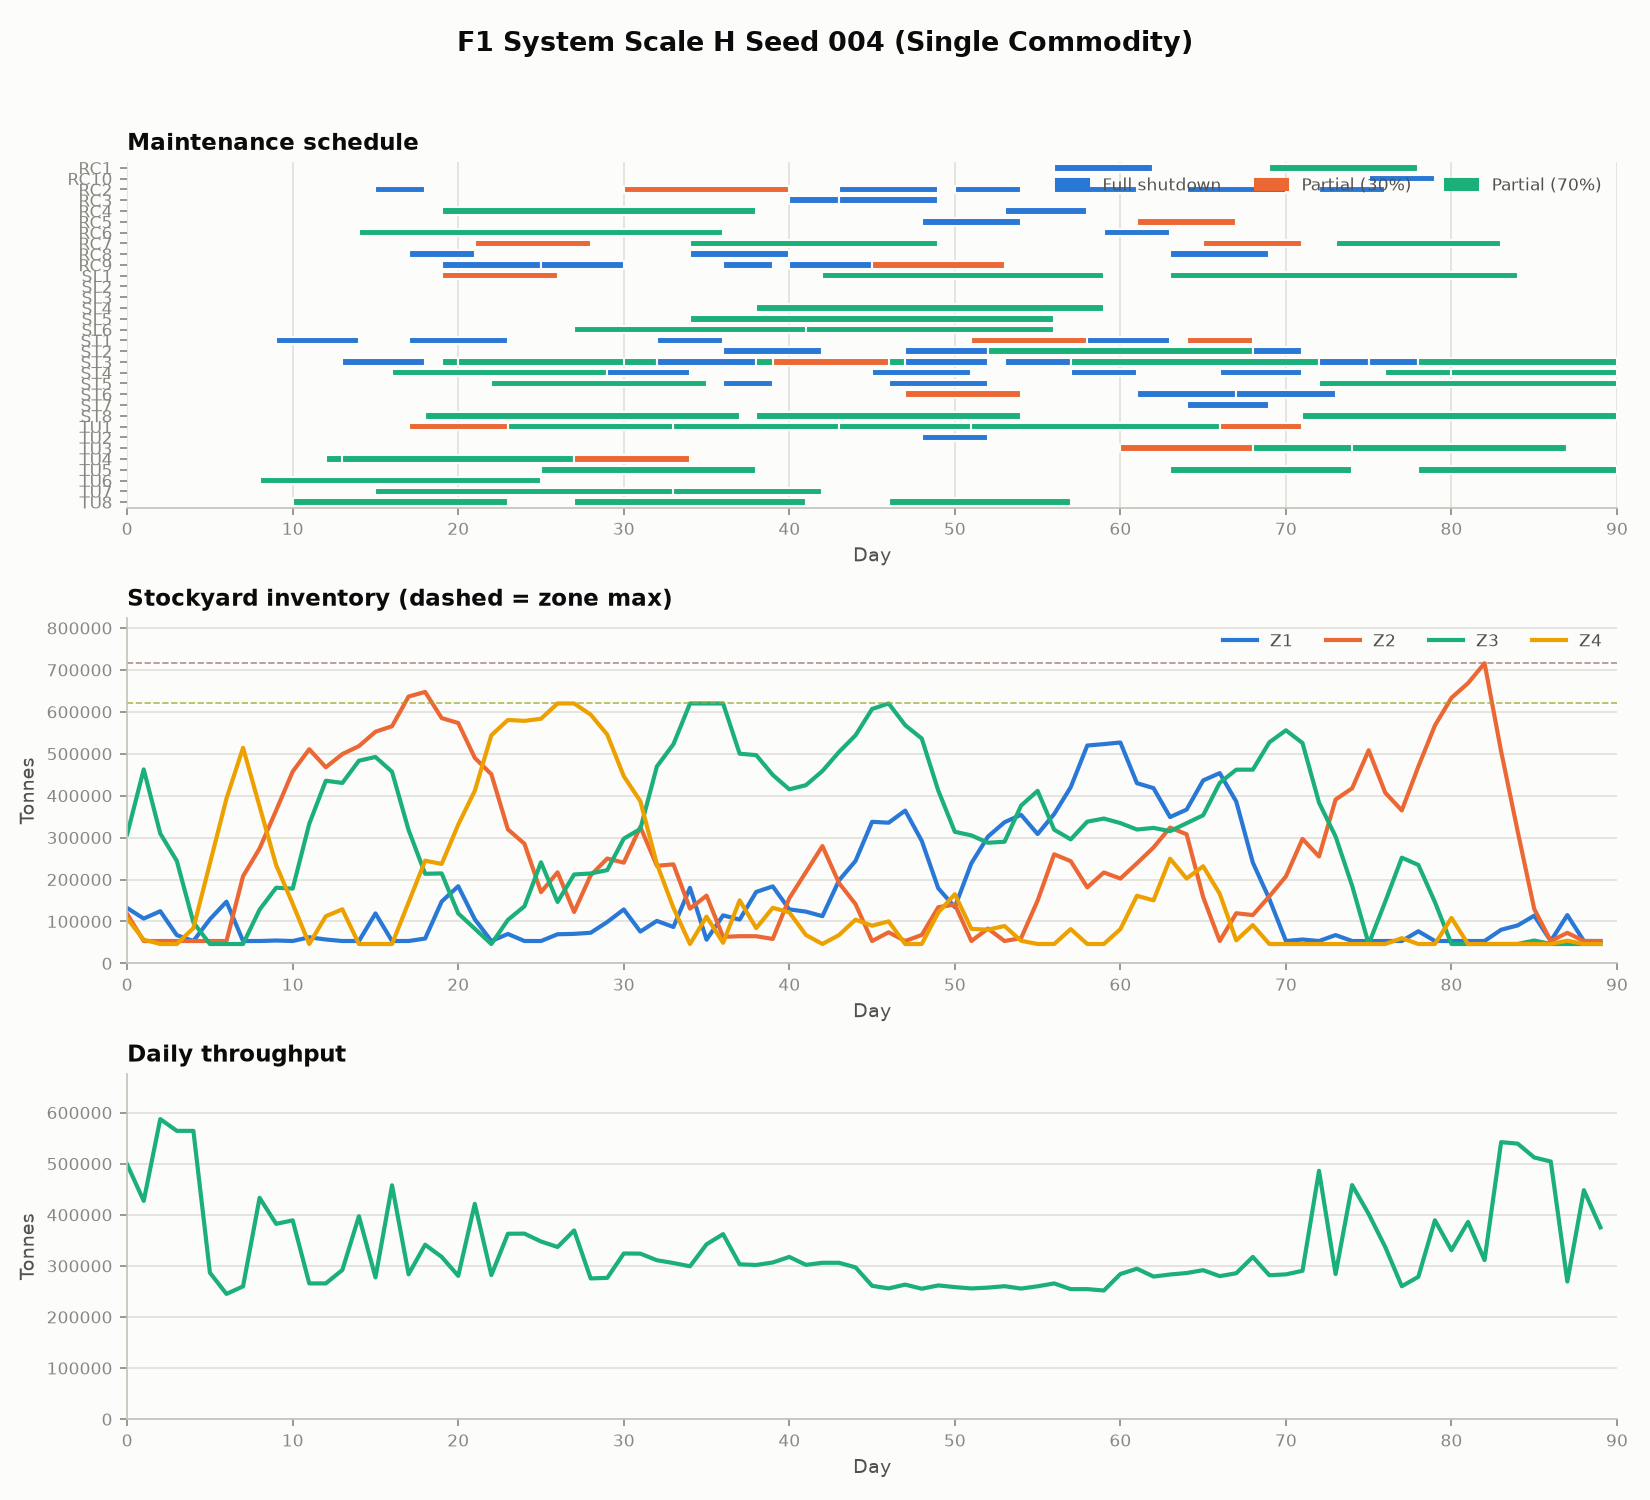

**results/plots/single_commodity\F1_system_scale_H_seed_005.png**

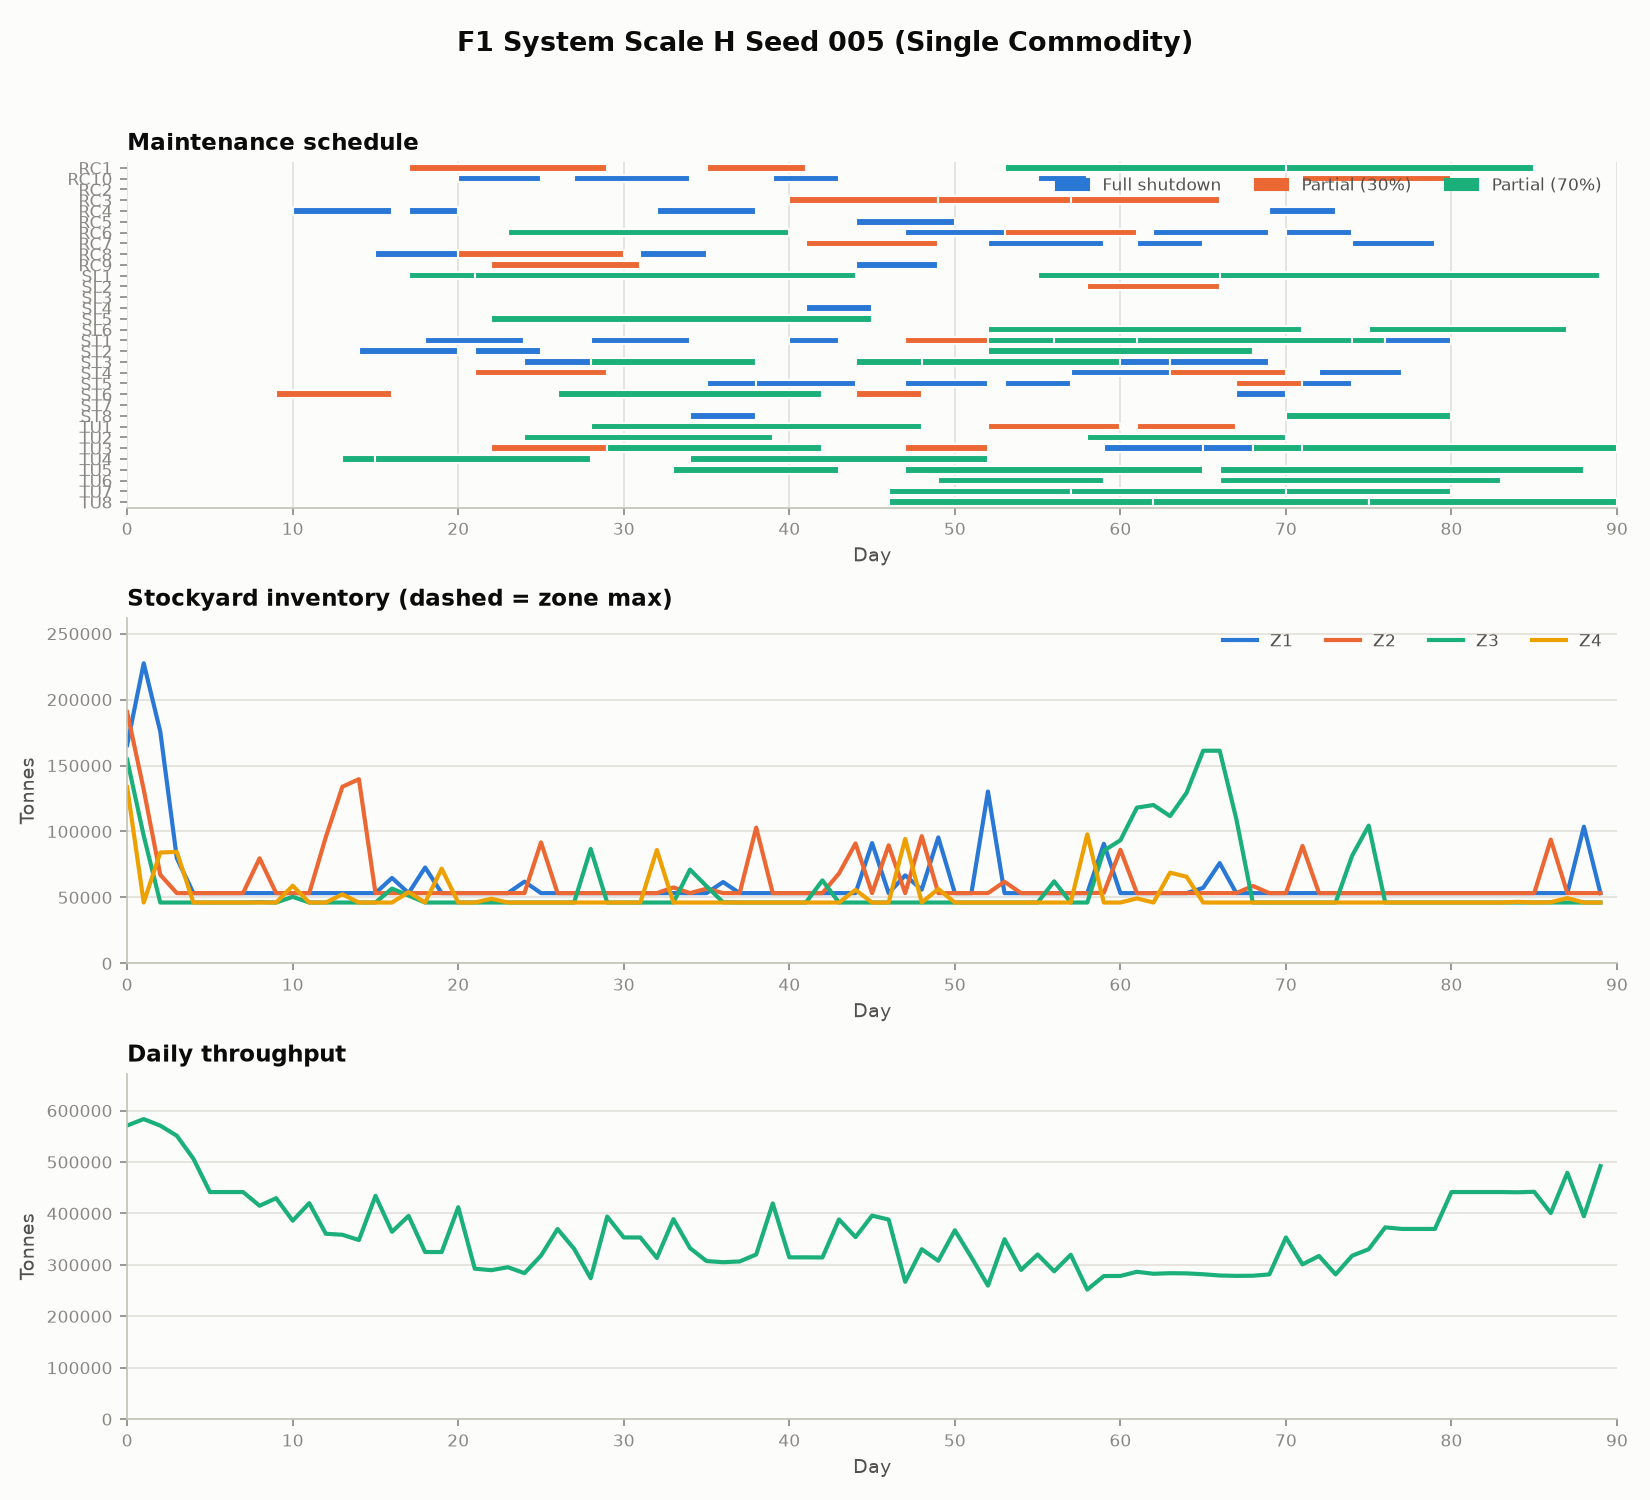

**results/plots/single_commodity\F1_system_scale_H_seed_006.png**

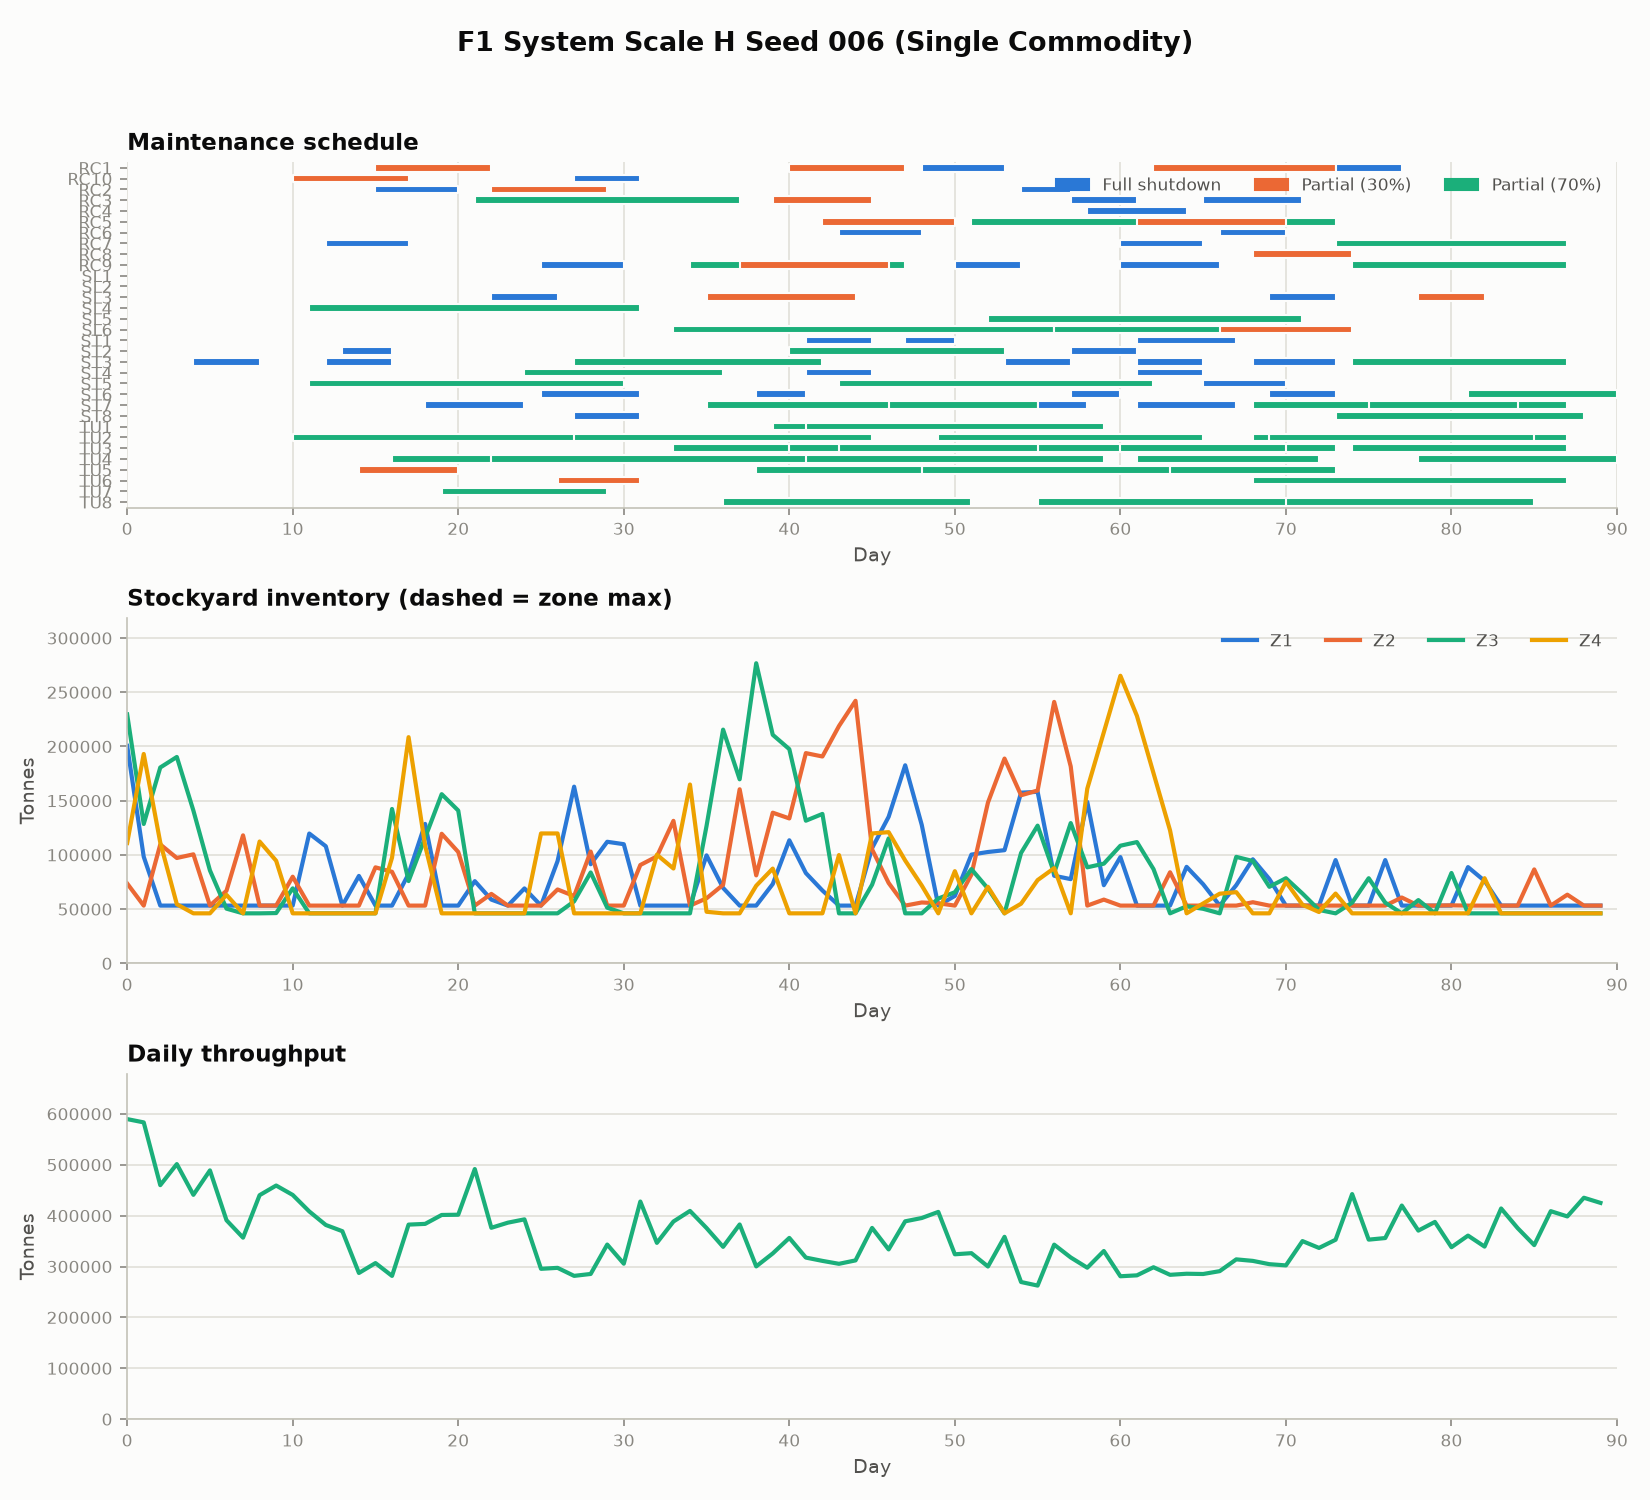

In [7]:
plot_paths = [result.get("plot_path") for result in results if result.get("plot_path")]

if not PREVIEW_PLOTS:
    print("Plot preview is turned off. Set PREVIEW_PLOTS = True in the parameter cell to preview PNGs here.")
elif not plot_paths:
    print("No PNG plots were created.")
    print("This usually means no scenario returned a solution, so no solution payload was available to plot.")
    print("Check the status/error columns in the results table above. If you see an error, fix that first and rerun from the optimisation cell.")
else:
    try:
        from IPython.display import Image, Markdown, display

        preview_paths = plot_paths[:MAX_PLOT_PREVIEWS]
        display(Markdown(f"Showing {len(preview_paths)} of {len(plot_paths)} generated PNG plot(s)."))
        for path in preview_paths:
            display(Markdown(f"**{path}**"))
            display(Image(filename=path))
    except Exception as exc:
        print(f"Plots were saved, but inline preview failed: {exc}")
        for path in plot_paths[:MAX_PLOT_PREVIEWS]:
            print(path)